# 04 – Clustering stations by their daily usage profile

**Question:** Are there different "types" of stations, based on *when* bikes leave and arrive during a normal weekday?

For each station we build a **profile** with 48 numbers:
- the share of the station's weekday traffic that is a *departure* in hour 0, 1, ..., 23
- the share that is an *arrival* in hour 0, 1, ..., 23

The 48 numbers add up to 100 %. Because we divide by the station's total, a small and a big station with the same rhythm get the same profile. We cluster on **shape**, not on size.

Method: k-means.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx  # downloads map tiles from the internet

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../report/figures")

# Free grey map from Kartverket (Norwegian Mapping Authority), CC BY 4.0, no API key needed
KARTVERKET_GREY = "https://cache.kartverket.no/v1/wmts/1.0.0/topograatone/default/webmercator/{z}/{y}/{x}.png"

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "station_hourly.parquet")
stations = pd.read_csv(PROCESSED_DIR / "stations.csv").set_index("station_id")

# Normal working days only (no weekends, no public holidays)
workdays = df[(df["weekday"] < 5) & (df["is_holiday"] == 0)]

departures = workdays.pivot_table(index="station_id", columns="hour", values="departures", aggfunc="sum", fill_value=0)
arrivals = workdays.pivot_table(index="station_id", columns="hour", values="arrivals", aggfunc="sum", fill_value=0)
total = departures.sum(axis=1) + arrivals.sum(axis=1)

# Stations with very few trips give noisy profiles, so we leave them out
MIN_TRIPS = 1000
keep = total >= MIN_TRIPS
print(f"Keeping {keep.sum()} of {len(keep)} stations (at least {MIN_TRIPS} weekday trips)")

departures = departures[keep]
arrivals = arrivals[keep]
total = total[keep]

departures.columns = [f"dep_{h:02d}" for h in departures.columns]
arrivals.columns = [f"arr_{h:02d}" for h in arrivals.columns]

profiles = pd.concat([departures, arrivals], axis=1).div(total, axis=0) * 100
print("Missing values:", profiles.isna().sum().sum())
profiles.head()

Keeping 263 of 272 stations (at least 1000 weekday trips)
Missing values: 0


,dep_00,dep_01,dep_02,dep_03,dep_04,dep_05,dep_06,dep_07,dep_08,dep_09,...,arr_14,arr_15,arr_16,arr_17,arr_18,arr_19,arr_20,arr_21,arr_22,arr_23
station_id,,,,,,,,,,,,,,,,,,,,,
377,0.622348,0.0,0.0,0.0,0.0,0.113154,0.763791,2.687412,6.251768,3.168317,...,2.178218,3.649222,4.045262,3.394625,3.479491,2.715700,2.121641,1.810467,1.471004,1.725601
380,0.698795,0.0,0.0,0.0,0.0,0.542169,2.975904,7.819277,9.566265,3.915663,...,1.144578,2.855422,6.048193,3.903614,2.951807,2.289157,2.253012,2.012048,1.710843,1.831325
381,0.359820,0.0,0.0,0.0,0.0,0.069965,0.349825,1.269365,3.398301,2.208896,...,2.688656,3.948026,6.666667,5.777111,4.487756,3.758121,2.488756,1.709145,1.769115,1.259370
382,0.720046,0.0,0.0,0.0,0.0,0.720046,2.620968,6.250000,4.896313,1.584101,...,1.756912,3.888249,6.682028,6.250000,5.241935,4.867512,3.456221,2.217742,2.678571,2.908986
383,0.271076,0.0,0.0,0.0,0.0,0.162646,1.761995,6.397398,10.788832,5.380862,...,2.195717,2.642993,3.022499,2.439686,2.114394,1.396042,1.002982,1.165628,0.772567,0.677690


We do **not** standardise the 48 columns. They are all in the same unit (% of the station's traffic), and standardising would blow up the night hours, where there is almost no traffic and mostly noise.

## 1. K-means: how many clusters?

- **Elbow plot**: the within-cluster sum of squares always goes down with more clusters; we look for where it stops dropping fast.
- **Silhouette score**: how well each station fits its own cluster compared to the nearest other cluster (higher is better, max 1).

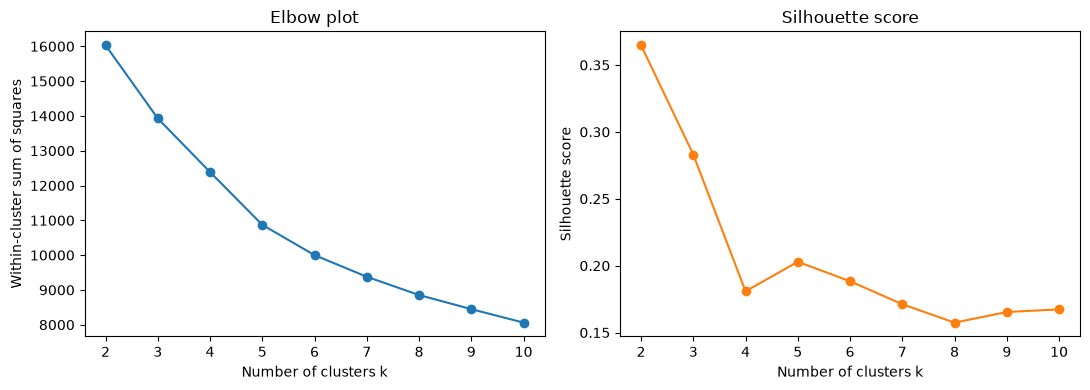

,k,inertia,silhouette
0,2,16031.538,0.365
1,3,13928.961,0.283
2,4,12386.850,0.181
3,5,10869.856,0.203
4,6,9999.727,0.188
5,7,9378.302,0.171
6,8,8853.705,0.157
7,9,8447.934,0.165
8,10,8060.601,0.167


In [3]:
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(profiles)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(profiles, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Within-cluster sum of squares")
axes[0].set_title("Elbow plot")
axes[1].plot(k_values, silhouettes, marker="o", color="tab:orange")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_choose_k.png", dpi=150)
plt.show()

pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette": silhouettes}).round(3)

There is no sharp elbow. The silhouette score is highest for k = 2 and still reasonable for k = 3, then drops a lot. We choose **k = 3** because it is easier to interpret than 2 and still has a clear structure.

## 2. K-means with k = 3

K-means numbers the clusters 0, 1, 2 in a random order. To make the results easier to read, we give each cluster a name based on what happens in the **morning rush (07–10)**:
- the cluster where many more bikes *arrive* than leave in the morning → **Workplace**
- the cluster where many more bikes *leave* than arrive in the morning → **Residential**
- the last one → **Mixed**

In [4]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
kmeans_labels = kmeans.fit_predict(profiles)

# The cluster centres are the average profile of each cluster
centres = pd.DataFrame(kmeans.cluster_centers_, columns=profiles.columns)

# Morning balance = % arriving minus % leaving between 07 and 10
morning = ["07", "08", "09"]
morning_balance = (
    centres[[f"arr_{h}" for h in morning]].sum(axis=1)
    - centres[[f"dep_{h}" for h in morning]].sum(axis=1)
)
names = {morning_balance.idxmax(): "Workplace", morning_balance.idxmin(): "Residential"}
names = {cluster: names.get(cluster, "Mixed") for cluster in range(K)}
centres.index = [names[cluster] for cluster in range(K)]

# Same order and colour for each cluster in every plot
ORDER = ["Residential", "Mixed", "Workplace"]
COLORS = {"Residential": "tab:red", "Mixed": "tab:green", "Workplace": "tab:blue"}

result = stations.loc[profiles.index, ["name", "lat", "lon"]].copy()
result["total_weekday_trips"] = total
result["kmeans_cluster"] = [names[label] for label in kmeans_labels]

print(result["kmeans_cluster"].value_counts().loc[ORDER])

kmeans_cluster
Residential    149
Mixed           82
Workplace       32
Name: count, dtype: int64


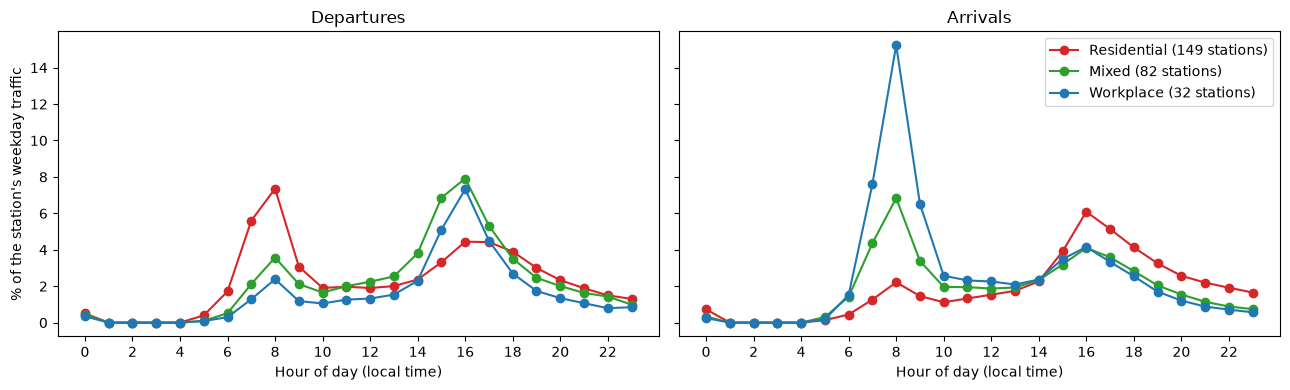

In [5]:
hours = range(24)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for name in ORDER:
    size = (result["kmeans_cluster"] == name).sum()
    label = f"{name} ({size} stations)"
    axes[0].plot(hours, centres.loc[name, departures.columns], marker="o", color=COLORS[name], label=label)
    axes[1].plot(hours, centres.loc[name, arrivals.columns], marker="o", color=COLORS[name], label=label)
axes[0].set_title("Departures")
axes[1].set_title("Arrivals")
for ax in axes:
    ax.set_xlabel("Hour of day (local time)")
    ax.set_xticks(range(0, 24, 2))
axes[0].set_ylabel("% of the station's weekday traffic")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "04_cluster_profiles.png", dpi=150)
plt.show()

In [6]:
# Summary table for the report: rush-hour shares and whether the cluster gains or loses bikes
summary = pd.DataFrame(index=ORDER)
summary["stations"] = result["kmeans_cluster"].value_counts()
summary["dep 07-10 (%)"] = centres[[f"dep_{h}" for h in ["07", "08", "09"]]].sum(axis=1)
summary["arr 07-10 (%)"] = centres[[f"arr_{h}" for h in ["07", "08", "09"]]].sum(axis=1)
summary["dep 15-18 (%)"] = centres[[f"dep_{h}" for h in ["15", "16", "17"]]].sum(axis=1)
summary["arr 15-18 (%)"] = centres[[f"arr_{h}" for h in ["15", "16", "17"]]].sum(axis=1)

# Departures per arrival, using the real trip counts (above 1 = the cluster loses bikes)
cluster_of = result["kmeans_cluster"]
summary["departures per arrival"] = departures.sum(axis=1).groupby(cluster_of).sum() / arrivals.sum(axis=1).groupby(cluster_of).sum()
summary["mean latitude"] = result.groupby("kmeans_cluster")["lat"].mean()
summary.round(2)

,stations,dep 07-10 (%),arr 07-10 (%),dep 15-18 (%),arr 15-18 (%),departures per arrival,mean latitude
Residential,149,16.03,4.94,12.18,15.13,1.15,59.92
Mixed,82,7.81,14.59,20.09,10.88,0.98,59.92
Workplace,32,4.86,29.36,16.93,10.97,0.60,59.91


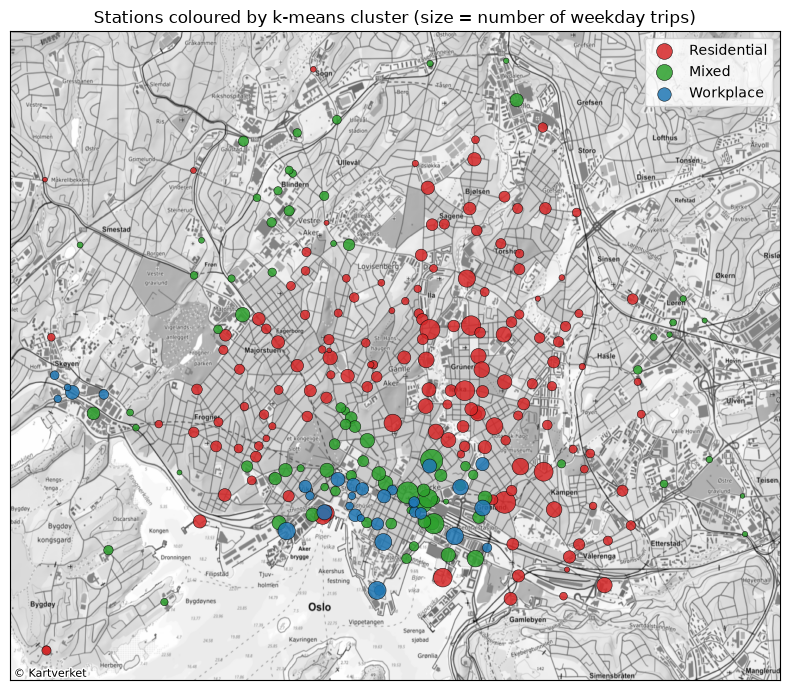

In [7]:
# Where are the clusters in the city?
fig, ax = plt.subplots(figsize=(8, 7))
for name in ORDER:
    in_cluster = result["kmeans_cluster"] == name
    ax.scatter(
        result.loc[in_cluster, "lon"], result.loc[in_cluster, "lat"],
        s=result.loc[in_cluster, "total_weekday_trips"] / 100, color=COLORS[name],
        edgecolor="black", linewidth=0.4, alpha=0.85, label=name, zorder=2,
    )
ctx.add_basemap(ax, crs="EPSG:4326", source=KARTVERKET_GREY, attribution="© Kartverket", zoom=14)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Stations coloured by k-means cluster (size = number of weekday trips)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "04_cluster_map.png", dpi=150)
plt.show()

In [8]:
# The 5 busiest stations in each cluster
result.sort_values("total_weekday_trips", ascending=False).groupby("kmeans_cluster").head(5).sort_values("kmeans_cluster")

,name,lat,lon,total_weekday_trips,kmeans_cluster
station_id,,,,,
489,Torggata,59.915983,10.751551,25518,Mixed
396,Kirkeristen,59.913000,10.746761,24439,Mixed
443,Sjøsiden 1 ved trappen,59.910143,10.752004,21129,Mixed
2328,The Hub,59.912472,10.750847,18205,Mixed
2315,Rostockgata,59.906920,10.760312,14171,Mixed
480,Helga Helgesens plass,59.912111,10.766194,24534,Residential
421,Alexander Kiellands Plass,59.928067,10.751203,20887,Residential
551,Olaf Ryes plass,59.922425,10.758182,20552,Residential
398,Ringnes Park,59.928434,10.759430,19699,Residential
